# COMPLETE ACNE DATASET ANALYSIS

Analysed Dataset structure:
```
Models/
└── yolo/
    └── data/
        └── dataset_final_preprocessed_acne04_only/
            ├── train/
            │   ├── images/
            │   └── labels/
            ├── val/
            │   ├── images/
            │   └── labels/
            └── test/
                ├── images/
                └── labels/
```
Filename convention:
```
  levle0_1.jpg -> acne level 0
  levle1_15.jpg -> acne level 1
  levle2_42.jpg -> acne level 2
  levle3_133.jpg -> acne level 3
```

YOLO annotation format: 
`class_id center_x center_y width height`

Example: `0 0.346080 0.697049 0.010925 0.009838`

In [111]:
from pathlib import Path
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

class YoloDatasetAnalyzer:
    VALID_EXT = {".jpg",".jpeg",".png",".bmp",".webp",".tif",".tiff"}
    SPLITS = ["train","valid","val","validation","test"]

    def __init__(self,dataset_dir,has_level=False,level_pattern=r"^(levle[^_]+)_",expected_classes=(0,)):
        self.dataset_dir=Path(dataset_dir)
        self.has_level=has_level
        self.level_pattern=level_pattern
        self.expected_classes=set(expected_classes)
        self.found_splits=[]
        self.images_df=pd.DataFrame()
        self.bboxes_df=pd.DataFrame()
        self.issues_df=pd.DataFrame()
        self.results={}
        self._detect_splits()

    # ============================================================
    # DATASET DISCOVERY
    # ============================================================

    def _detect_splits(self):
        self.found_splits=[s for s in self.SPLITS if (self.dataset_dir/s/"images").exists() or (self.dataset_dir/s/"labels").exists()]
        if not self.found_splits:
            raise FileNotFoundError(f"No train/valid/test splits found in: {self.dataset_dir.resolve()}")

    def get_image_files(self,images_dir):
        if not images_dir.exists():
            return []
        return sorted([f for f in images_dir.iterdir() if f.is_file() and f.suffix.lower() in self.VALID_EXT])

    # ============================================================
    # LEVEL
    # ============================================================

    def extract_acne_level(self,filename):
        if not self.has_level:
            return None
        match=re.match(self.level_pattern,filename.lower())
        return match.group(1) if match else None

    # ============================================================
    # YOLO LABEL READING
    # ============================================================

    @staticmethod
    def read_yolo_labels(label_path):
        annotations=[]
        if not label_path.exists():
            return annotations
        try:
            lines=label_path.read_text(encoding="utf-8").splitlines()
        except Exception:
            return annotations
        for line_number,line in enumerate(lines,1):
            line=line.strip()
            if not line:
                continue
            parts=line.split()
            if len(parts)!=5:
                annotations.append({"valid":False,"line":line_number,"raw":line})
                continue
            try:
                annotations.append({"valid":True,"line":line_number,"class_id":int(parts[0]),"cx":float(parts[1]),"cy":float(parts[2]),"width":float(parts[3]),"height":float(parts[4])})
            except ValueError:
                annotations.append({"valid":False,"line":line_number,"raw":line})
        return annotations

    # ============================================================
    # DATA COLLECTION
    # ============================================================

    def analyze(self):
        image_records=[]
        bbox_records=[]
        issues=[]
        for split in self.found_splits:
            images_dir=self.dataset_dir/split/"images"
            labels_dir=self.dataset_dir/split/"labels"
            image_files=self.get_image_files(images_dir)
            label_files=list(labels_dir.glob("*.txt")) if labels_dir.exists() else []
            image_map={f.stem:f for f in image_files}
            label_map={f.stem:f for f in label_files}
            for stem in set(label_map)-set(image_map):
                issues.append({"type":"label_without_image","split":split,"file":f"{stem}.txt"})
            for stem in set(image_map)-set(label_map):
                issues.append({"type":"image_without_label","split":split,"file":image_map[stem].name})
            for stem,img_path in image_map.items():
                level=self.extract_acne_level(img_path.name)
                try:
                    with Image.open(img_path) as img:
                        img_w,img_h=img.size
                except Exception as error:
                    issues.append({"type":"corrupted_image","split":split,"file":img_path.name,"details":str(error)})
                    continue
                label_path=label_map.get(stem)
                annotations=self.read_yolo_labels(label_path) if label_path else []
                valid_annotations=[a for a in annotations if a.get("valid",False)]
                invalid_annotations=[a for a in annotations if not a.get("valid",False)]
                for a in invalid_annotations:
                    issues.append({"type":"invalid_annotation_format","split":split,"file":f"{stem}.txt","line":a["line"]})
                image_record={"split":split,"image":img_path.name,"width_px":img_w,"height_px":img_h,"image_area_px":img_w*img_h,"lesion_count":len(valid_annotations),"label_exists":label_path is not None,"invalid_annotations":len(invalid_annotations)}
                if self.has_level:
                    image_record["level"]=level
                image_records.append(image_record)
                for bbox_id,a in enumerate(valid_annotations):
                    class_id=a["class_id"]
                    cx,cy,bw,bh=a["cx"],a["cy"],a["width"],a["height"]
                    if class_id not in self.expected_classes:
                        issues.append({"type":"unexpected_class","split":split,"file":f"{stem}.txt","line":a["line"],"value":class_id})
                    if not (0<=cx<=1):
                        issues.append({"type":"center_x_out_of_range","split":split,"file":f"{stem}.txt","line":a["line"],"value":cx})
                    if not (0<=cy<=1):
                        issues.append({"type":"center_y_out_of_range","split":split,"file":f"{stem}.txt","line":a["line"],"value":cy})
                    if not (0<bw<=1):
                        issues.append({"type":"width_out_of_range","split":split,"file":f"{stem}.txt","line":a["line"],"value":bw})
                    if not (0<bh<=1):
                        issues.append({"type":"height_out_of_range","split":split,"file":f"{stem}.txt","line":a["line"],"value":bh})
                    bw_px,bh_px=bw*img_w,bh*img_h
                    x1_rel,y1_rel,x2_rel,y2_rel=cx-bw/2,cy-bh/2,cx+bw/2,cy+bh/2
                    x1_px,y1_px,x2_px,y2_px=x1_rel*img_w,y1_rel*img_h,x2_rel*img_w,y2_rel*img_h
                    outside=x1_rel<0 or y1_rel<0 or x2_rel>1 or y2_rel>1
                    if outside:
                        issues.append({"type":"bbox_outside_image","split":split,"file":f"{stem}.txt","line":a["line"]})
                    bbox_record={"split":split,"image":img_path.name,"bbox_id":bbox_id,"class_id":class_id,"center_x":cx,"center_y":cy,"width_relative":bw,"height_relative":bh,"width_px":bw_px,"height_px":bh_px,"area_relative":bw*bh,"area_px":bw_px*bh_px,"x1_rel":x1_rel,"y1_rel":y1_rel,"x2_rel":x2_rel,"y2_rel":y2_rel,"x1_px":x1_px,"y1_px":y1_px,"x2_px":x2_px,"y2_px":y2_px,"outside":outside}
                    if self.has_level:
                        bbox_record["level"]=level
                    bbox_records.append(bbox_record)
        # self.images_df=pd.DataFrame(image_records)
        # self.bboxes_df=pd.DataFrame(bbox_records)
        # self.issues_df=pd.DataFrame(issues)

        self.images_df=pd.DataFrame(image_records)
        if self.has_level and "level" in self.images_df.columns:
            self.images_df["level"]=self.images_df["level"].astype("string")
        self.bboxes_df=pd.DataFrame(bbox_records)
        if self.has_level and "level" in self.bboxes_df.columns:
            self.bboxes_df["level"]=self.bboxes_df["level"].astype("string")
        self.issues_df=pd.DataFrame(issues)

        return self.images_df,self.bboxes_df,self.issues_df

    # ============================================================
    # BASIC DATASET OVERVIEW
    # ============================================================

    def dataset_overview(self):
        if self.images_df.empty:
            result=pd.DataFrame()
            self.results["overview"]=result
            return result
        result=pd.DataFrame({"metric":["total_images","total_lesions","mean_lesions_per_image","median_lesions_per_image","min_lesions_per_image","max_lesions_per_image","dataset_issues"],"value":[len(self.images_df),len(self.bboxes_df),self.images_df["lesion_count"].mean(),self.images_df["lesion_count"].median(),self.images_df["lesion_count"].min(),self.images_df["lesion_count"].max(),len(self.issues_df)]})
        self.results["overview"]=result
        return result

    def split_analysis(self):
        if self.images_df.empty:
            return pd.DataFrame()
        result=self.images_df.groupby("split").agg(total_images=("image","count"),background_images=("lesion_count",lambda x:(x==0).sum()),images_with_lesions=("lesion_count",lambda x:(x>0).sum()),total_lesions=("lesion_count","sum"))
        result["background_ratio_%"]=result["background_images"]/result["total_images"]*100
        result["dataset_share_%"]=result["total_images"]/len(self.images_df)*100
        result=result.reset_index()
        self.results["split"]=result
        return result

    def lesion_count_analysis(self):
        if self.images_df.empty:
            return pd.DataFrame()
        edges=[-1,0,2,5,10,20,30,50,100,200,np.inf]
        labels=["0","1-2","3-5","6-10","11-20","21-30","31-50","51-100","101-200","200+"]
        temp=self.images_df.copy()
        temp["lesion_bin"]=pd.cut(temp["lesion_count"],bins=edges,labels=labels)
        result=temp["lesion_bin"].value_counts(sort=False).reset_index()
        result.columns=["lesion_count_range","images"]
        result["percentage"]=result["images"]/len(self.images_df)*100
        self.results["lesion_count"]=result
        self.images_df["lesion_bin"]=temp["lesion_bin"]
        return result

    # ============================================================
    # BBOX ANALYSIS
    # ============================================================

    def bbox_statistics(self):
        if self.bboxes_df.empty:
            return pd.DataFrame()
        cols=["width_relative","height_relative","area_relative"]
        result=self.bboxes_df[cols].agg(["mean","std","median","min","max"]).T
        self.results["bbox_statistics"]=result
        return result

    def bbox_area_analysis(self):
        if self.bboxes_df.empty:
            return pd.DataFrame()
        edges=[0,0.0001,0.0005,0.001,0.0025,0.005,0.01,0.02,0.05,1]
        labels=["<0.01%","0.01-0.05%","0.05-0.1%","0.1-0.25%","0.25-0.5%","0.5-1%","1-2%","2-5%",">5%"]
        temp=self.bboxes_df.copy()
        temp["area_bin"]=pd.cut(temp["area_relative"],bins=edges,labels=labels,include_lowest=True)
        result=temp["area_bin"].value_counts(sort=False).reset_index()
        result.columns=["relative_area","lesions"]
        result["percentage"]=result["lesions"]/len(self.bboxes_df)*100
        self.results["bbox_area"]=result
        self.bboxes_df["area_bin"]=temp["area_bin"]
        return result

    # ============================================================
    # LEVEL ANALYSIS
    # ============================================================

    def level_analysis(self):
        if not self.has_level:
            return None
        if self.images_df.empty or "level" not in self.images_df.columns:
            return pd.DataFrame()
        levels=sorted(self.images_df["level"].dropna().unique())
        result=self.images_df.groupby("level").size().reindex(levels,fill_value=0).reset_index(name="images")
        result["percentage"]=result["images"]/len(self.images_df)*100
        self.results["level_distribution"]=result
        return result

    def level_split_analysis(self):
        if not self.has_level:
            return None
        if self.images_df.empty:
            return pd.DataFrame()
        result=pd.crosstab(self.images_df["split"],self.images_df["level"])
        levels=sorted(self.images_df["level"].dropna().unique())
        result=result.reindex(columns=levels,fill_value=0)
        result.index.name="split"
        result=result.reset_index()
        self.results["level_by_split"]=result
        return result

    def lesion_count_by_level(self):
        if not self.has_level:
            return None
        if self.images_df.empty:
            return pd.DataFrame()
        result=self.images_df.groupby("level")["lesion_count"].agg(images="count",total_lesions="sum",mean="mean",median="median",minimum="min",maximum="max").reset_index()
        self.results["lesion_count_by_level"]=result
        return result

    def bbox_statistics_by_level(self):
        if not self.has_level:
            return None
        if self.bboxes_df.empty:
            return pd.DataFrame()
        result=self.bboxes_df.groupby("level")[["width_relative","height_relative","area_relative"]].agg(["mean","std","median","min","max"])
        self.results["bbox_statistics_by_level"]=result
        return result

    # ============================================================
    # QUALITY / VALIDATION
    # ============================================================

    def validation_analysis(self):
        if self.images_df.empty:
            return {}
        zero_annotation_images=self.images_df[self.images_df["lesion_count"]==0]
        images_without_labels=self.images_df[~self.images_df["label_exists"]]
        result={"zero_annotation_images":len(zero_annotation_images),"images_without_labels":len(images_without_labels),"issues_total":len(self.issues_df)}
        if self.has_level and "level" in self.images_df.columns:
            result["unknown_level_images"]=int(self.images_df["level"].isna().sum())
        else:
            result["unknown_level_images"]=None
        if self.issues_df.empty:
            result["issue_summary"]=pd.DataFrame(columns=["issue_type","count"])
        else:
            issue_summary=self.issues_df["type"].value_counts().reset_index()
            issue_summary.columns=["issue_type","count"]
            result["issue_summary"]=issue_summary
        self.results["validation"]=result
        return result

    # ============================================================
    # OUTSIDE BBOX ANALYSIS
    # ============================================================

    def outside_bbox_analysis(self):
        if self.bboxes_df.empty:
            return pd.DataFrame()
        result=self.bboxes_df.groupby("split")["outside"].agg(total_bboxes="count",outside_bboxes="sum").reset_index()
        result["outside_ratio_%"]=result["outside_bboxes"]/result["total_bboxes"]*100
        self.results["outside_bbox"]=result
        return result

    # ============================================================
    # PLOTS
    # ============================================================

    def plot_lesion_distribution(self):
        result=self.results.get("lesion_count",self.lesion_count_analysis())
        if result is None or result.empty:
            return
        plt.figure(figsize=(10,5))
        plt.bar(result["lesion_count_range"].astype(str),result["images"],edgecolor="black")
        plt.xlabel("Number of lesions per image")
        plt.ylabel("Number of images")
        plt.title(f"Lesion Density Distribution - {self.dataset_dir.name}")
        plt.xticks(rotation=45)
        plt.grid(axis="y",linestyle="--",alpha=0.7)
        plt.tight_layout()
        plt.show()

    def plot_level_distribution(self):
        if not self.has_level:
            return
        result=self.results.get("level_distribution",self.level_analysis())
        if result is None or result.empty:
            return
        plt.figure(figsize=(8,5))
        plt.bar(result["level"].astype(str),result["images"],edgecolor="black")
        plt.xlabel("Acne level")
        plt.ylabel("Number of images")
        plt.title(f"Acne Level Distribution - {self.dataset_dir.name}")
        plt.tight_layout()
        plt.show()

    def plot_lesions_by_level(self):
        if not self.has_level or self.images_df.empty:
            return
        levels=sorted(self.images_df["level"].dropna().unique())
        data=[self.images_df.loc[self.images_df["level"]==level,"lesion_count"] for level in levels]
        if not data:
            return
        plt.figure(figsize=(8,5))
        plt.boxplot(data,tick_labels=[f"Level {level}" for level in levels])
        plt.xlabel("Acne level")
        plt.ylabel("Number of lesions")
        plt.title(f"Lesion Count Distribution by Acne Level - {self.dataset_dir.name}")
        plt.tight_layout()
        plt.show()

    def plot_split_distribution(self):
        result=self.results.get("split",self.split_analysis())
        if result is None or result.empty:
            return
        plt.figure(figsize=(8,5))
        plt.bar(result["split"],result["total_images"],edgecolor="black")
        plt.xlabel("Split")
        plt.ylabel("Number of images")
        plt.title(f"Dataset Split Distribution - {self.dataset_dir.name}")
        plt.tight_layout()
        plt.show()

    def plot_bbox_area_distribution(self):
        result=self.results.get("bbox_area",self.bbox_area_analysis())
        if result is None or result.empty:
            return
        plt.figure(figsize=(10,5))
        plt.bar(result["relative_area"].astype(str),result["lesions"],edgecolor="black")
        plt.xlabel("Relative bbox area")
        plt.ylabel("Number of lesions")
        plt.title(f"Bounding Box Area Distribution - {self.dataset_dir.name}")
        plt.xticks(rotation=45)
        plt.grid(axis="y",linestyle="--",alpha=0.7)
        plt.tight_layout()
        plt.show()

    # ============================================================
    # RANDOM OUTSIDE BBOX VISUALIZATION
    # ============================================================

    def plot_random_outside_bbox(self,seed=None):
        if self.issues_df.empty or self.bboxes_df.empty:
            print("No dataset issues or bounding boxes available.")
            return None
        outside=self.issues_df[self.issues_df["type"]=="bbox_outside_image"]
        if outside.empty:
            print("No out-of-bounds bounding boxes found.")
            return None
        if seed is not None:
            random.seed(seed)
        issue=outside.sample(1,random_state=seed).iloc[0]
        split=issue["split"]
        image_stem=Path(issue["file"]).stem
        candidates=self.images_df[(self.images_df["split"]==split)&(self.images_df["image"].map(lambda x:Path(x).stem)==image_stem)]
        if candidates.empty:
            print("Image corresponding to the selected issue was not found.")
            return None
        image_name=candidates.iloc[0]["image"]
        image_path=self.dataset_dir/split/"images"/image_name
        image=Image.open(image_path).convert("RGB")
        boxes=self.bboxes_df[(self.bboxes_df["split"]==split)&(self.bboxes_df["image"]==image_name)].copy()
        fig,ax=plt.subplots(figsize=(12,10))
        ax.imshow(image)
        for _,b in boxes.iterrows():
            x,y=b["x1_px"],b["y1_px"]
            width,height=b["width_px"],b["height_px"]
            edgecolor="red" if b["outside"] else "limegreen"
            linewidth=3 if b["outside"] else 1
            ax.add_patch(Rectangle((x,y),width,height,fill=False,edgecolor=edgecolor,linewidth=linewidth))
            ax.text(x,y,str(int(b["bbox_id"])),fontsize=9,color=edgecolor,fontweight="bold")
        ax.set_title(f"{image_name} | {split}")
        ax.axis("off")
        plt.tight_layout()
        plt.show()
        columns=["bbox_id","class_id","center_x","center_y","width_relative","height_relative","x1_rel","y1_rel","x2_rel","y2_rel","x1_px","y1_px","x2_px","y2_px","outside"]
        return boxes[columns].round(4)

    # ============================================================
    # PRINT SUMMARY
    # ============================================================

    def print_summary(self):
        print("="*70)
        print(f"DATASET: {self.dataset_dir.name}")
        print("="*70)
        print(f"Path: {self.dataset_dir.resolve()}")
        print(f"Level attribute: {'YES' if self.has_level else 'NO'}")
        print(f"Splits: {', '.join(self.found_splits)}")
        print(f"Images: {len(self.images_df):,}")
        print(f"Bounding boxes: {len(self.bboxes_df):,}")
        print(f"Issues: {len(self.issues_df):,}")
        if not self.images_df.empty:
            print(f"Mean lesions/image: {self.images_df['lesion_count'].mean():.2f}")
            print(f"Median lesions/image: {self.images_df['lesion_count'].median():.2f}")
            print(f"Min lesions/image: {self.images_df['lesion_count'].min()}")
            print(f"Max lesions/image: {self.images_df['lesion_count'].max()}")
            print(f"Images with 0 lesions: {(self.images_df['lesion_count']==0).sum():,}")
        if self.has_level and "level" in self.images_df.columns:
            print(f"Images with unknown level: {self.images_df['level'].isna().sum():,}")
        if not self.issues_df.empty:
            print("\nIssues:")
            print(self.issues_df["type"].value_counts().to_string())
        print("="*70)

    # ============================================================
    # RUN COMPLETE ANALYSIS
    # ============================================================

    def run(self,show_plots=True,show_tables=True,plot_outside_bbox=False):
        self.analyze()
        self.dataset_overview()
        self.split_analysis()
        self.lesion_count_analysis()
        self.bbox_statistics()
        self.bbox_area_analysis()
        self.outside_bbox_analysis()
        self.validation_analysis()
        if self.has_level:
            self.level_analysis()
            self.level_split_analysis()
            self.lesion_count_by_level()
            self.bbox_statistics_by_level()
        self.print_summary()
        if show_tables:
            print("\nDATASET OVERVIEW")
            display(self.results["overview"])
            print("\nSPLIT ANALYSIS")
            display(self.results["split"])
            print("\nLESION COUNT DISTRIBUTION")
            display(self.results["lesion_count"])
            if not self.bboxes_df.empty:
                print("\nBOUNDING BOX STATISTICS")
                display(self.results["bbox_statistics"])
                print("\nBOUNDING BOX AREA DISTRIBUTION")
                display(self.results["bbox_area"])
                print("\nOUTSIDE BBOX ANALYSIS")
                display(self.results["outside_bbox"])
            print("\nVALIDATION")
            validation=self.results["validation"]
            print(f"Images with zero annotations: {validation['zero_annotation_images']:,}")
            print(f"Images without labels: {validation['images_without_labels']:,}")
            if self.has_level:
                print(f"Images with unknown acne level: {validation['unknown_level_images']:,}")
            if not validation["issue_summary"].empty:
                display(validation["issue_summary"])
            if self.has_level:
                print("\nACNE LEVEL DISTRIBUTION")
                display(self.results["level_distribution"])
                print("\nACNE LEVEL BY SPLIT")
                display(self.results["level_by_split"])
                print("\nLESION COUNT BY ACNE LEVEL")
                display(self.results["lesion_count_by_level"])
                if not self.results["bbox_statistics_by_level"].empty:
                    print("\nBOUNDING BOX STATISTICS BY ACNE LEVEL")
                    display(self.results["bbox_statistics_by_level"])
                    
        if show_plots:
            self.plot_split_distribution()
            self.plot_lesion_distribution()
            self.plot_bbox_area_distribution()
            if self.has_level:
                self.plot_level_distribution()
                self.plot_lesions_by_level()
            if plot_outside_bbox:
                self.plot_random_outside_bbox()
        return self.results

## acne04 not yet changed

DATASET: dataset_final_preprocessed_acne04_only
Path: D:\studia\DermaAI\Models\yolo\data\dataset_final_preprocessed_acne04_only
Level attribute: YES
Splits: train, valid, test
Images: 1,164
Bounding boxes: 31,423
Issues: 107
Mean lesions/image: 27.00
Median lesions/image: 19.00
Min lesions/image: 1
Max lesions/image: 434
Images with 0 lesions: 0
Images with unknown level: 0

Issues:
type
bbox_outside_image    107

DATASET OVERVIEW


,metric,value
0,total_images,1164.000000
1,total_lesions,31423.000000
2,mean_lesions_per_image,26.995704
3,median_lesions_per_image,19.000000
4,min_lesions_per_image,1.000000
5,max_lesions_per_image,434.000000
6,dataset_issues,107.000000



SPLIT ANALYSIS


,split,total_images,background_images,images_with_lesions,total_lesions,background_ratio_%,dataset_share_%
0,test,116,0,116,2780,0.0,9.965636
1,train,805,0,805,21966,0.0,69.158076
2,valid,243,0,243,6677,0.0,20.876289



LESION COUNT DISTRIBUTION


...

level,split,levle0,levle1,levle2,levle3
0,test,45,63,7,1
1,train,315,386,90,14
2,valid,100,108,28,7



LESION COUNT BY ACNE LEVEL


,level,images,total_lesions,mean,median,minimum,maximum
0,levle0,460,7549,16.410870,12.0,1,109
1,levle1,557,15141,27.183124,22.0,1,143
2,levle2,125,6343,50.744000,44.0,1,174
3,levle3,22,2390,108.636364,73.5,17,434



BOUNDING BOX STATISTICS BY ACNE LEVEL


width_relative                                         height_relative  \
                 mean       std    median       min       max            mean   
level                                                                           
levle0       0.013521  0.006902  0.012211  0.001285  0.091667        0.012436   
levle1       0.014992  0.008029  0.012853  0.001221  0.116967        0.014019   
levle2       0.024449  0.081039  0.014781  0.001285  1.000000        0.023203   
levle3       0.023918  0.021602  0.017352  0.001285  0.182540        0.021642   

                                               area_relative            \
             std    median       min       max          mean       std   
level                                                                    
levle0  0.006644  0.010995  0.001157  0.087010      0.000212  0.000297   
levle1  0.007496  0.012153  0.001157  0.107230      0.000268  0.000372   
levle2  0.078910  0.014093  0.001157  1.000000      0.006950  0.077188   
levle3  0.017471  0.016782  0.001157  0.185049      0.000855  0.001852   

                                      
          median       min       max  
level                                 
levle0  0.000134  0.000001  0.006382  
levle1  0.000164  0.000001  0.012319  
levle2  0.000214  0.000001  1.000000  
levle3  0.000292  0.000001  0.023228

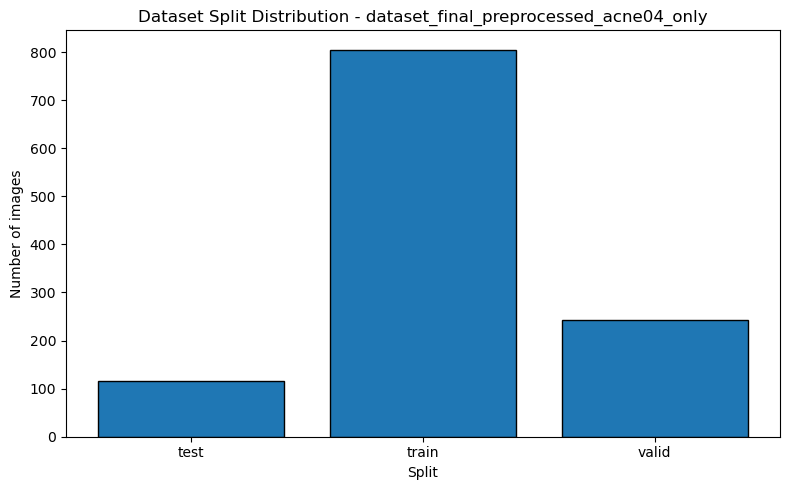

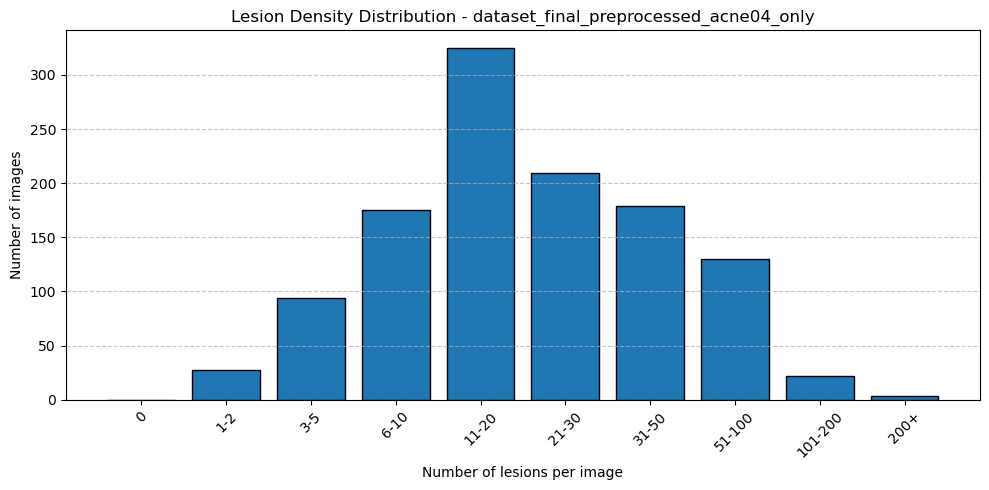

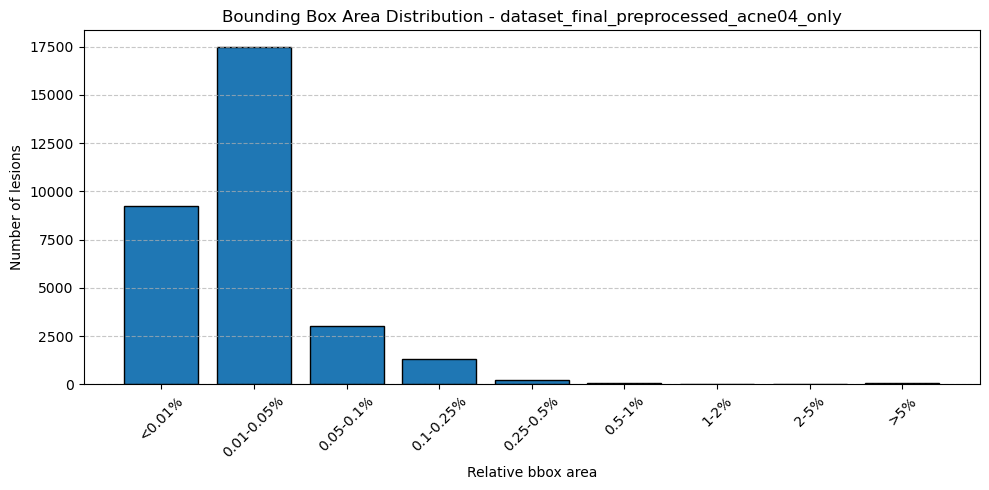

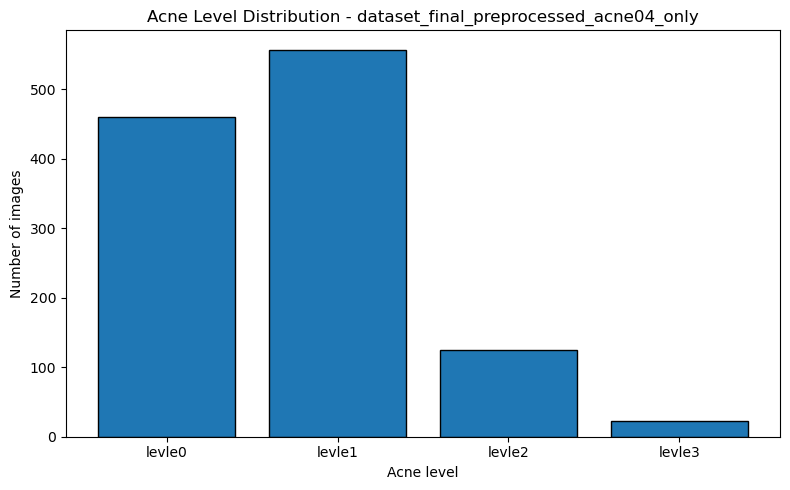

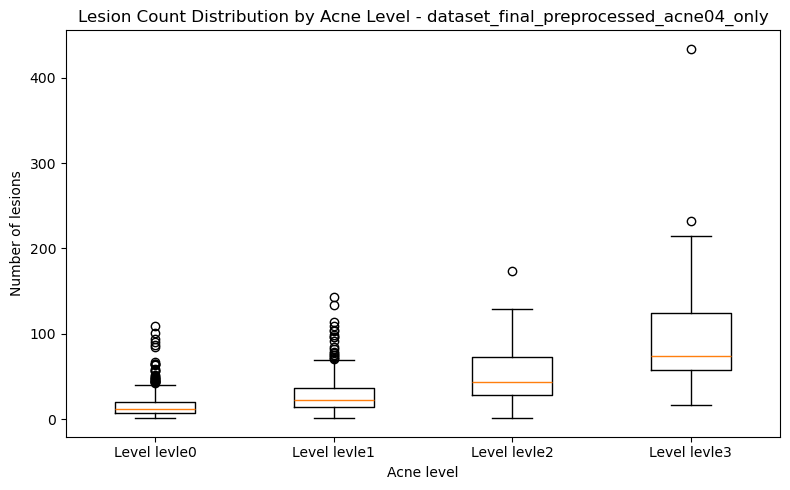

In [112]:
acne04=YoloDatasetAnalyzer(r"..\data\dataset_final_preprocessed_acne04_only",has_level=True)
results_acne04=acne04.run()

## acnescu train split

DATASET: ACNESCU.v1i.yolo26_bbox_acne_only_preprocessed
Path: D:\studia\DermaAI\Models\yolo\data\ACNESCU.v1i.yolo26_bbox_acne_only_preprocessed
Level attribute: NO
Splits: train
Images: 220
Bounding boxes: 12,555
Issues: 56
Mean lesions/image: 57.07
Median lesions/image: 49.50
Min lesions/image: 3
Max lesions/image: 269
Images with 0 lesions: 0

Issues:
type
label_without_image    55
bbox_outside_image      1

DATASET OVERVIEW


,metric,value
0,total_images,220.000000
1,total_lesions,12555.000000
2,mean_lesions_per_image,57.068182
3,median_lesions_per_image,49.500000
4,min_lesions_per_image,3.000000
5,max_lesions_per_image,269.000000
6,dataset_issues,56.000000



SPLIT ANALYSIS


,split,total_images,background_images,images_with_lesions,total_lesions,background_ratio_%,dataset_share_%
0,train,220,0,220,12555,0.0,100.0



LESION COUNT DISTRIBUTION


...

,relative_area,lesions,percentage
0,<0.01%,9096,72.449223
1,0.01-0.05%,3095,24.651533
2,0.05-0.1%,239,1.903624
3,0.1-0.25%,96,0.764636
4,0.25-0.5%,20,0.159299
5,0.5-1%,9,0.071685
6,1-2%,0,0.000000
7,2-5%,0,0.000000
8,>5%,0,0.000000



OUTSIDE BBOX ANALYSIS


,split,total_bboxes,outside_bboxes,outside_ratio_%
0,train,12555,1,0.007965



VALIDATION
Images with zero annotations: 0
Images without labels: 0


,issue_type,count
0,label_without_image,55
1,bbox_outside_image,1


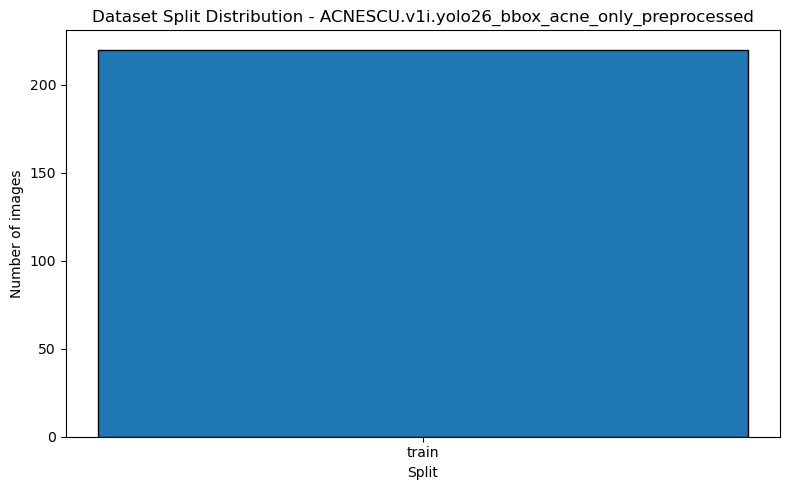

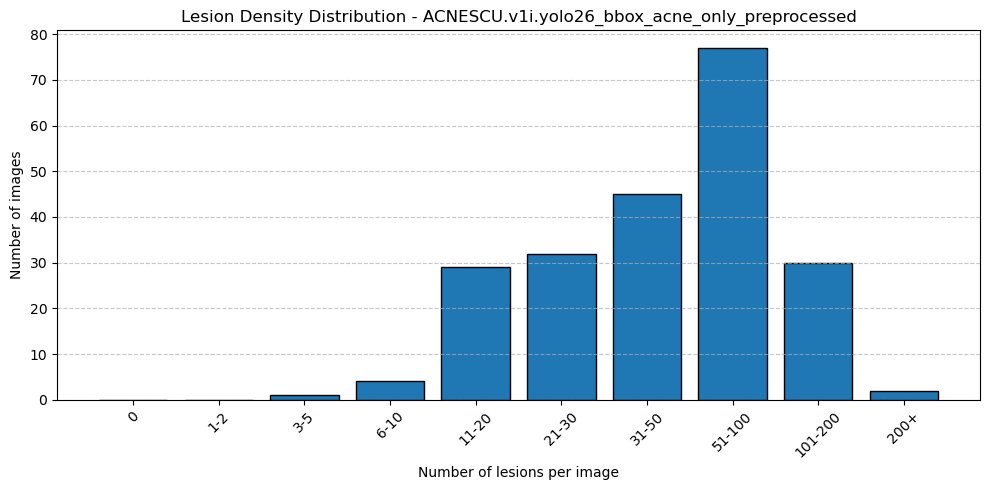

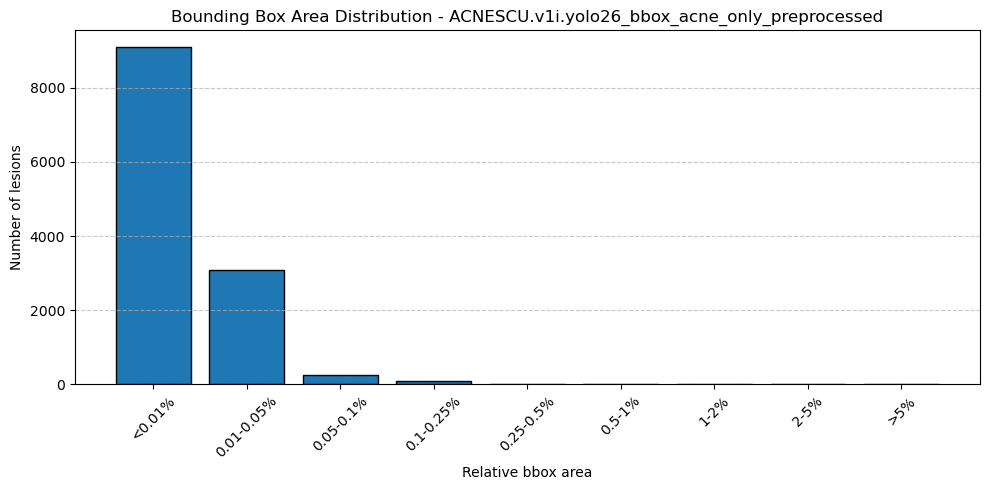

In [113]:
acnescu=YoloDatasetAnalyzer(r"..\data\ACNESCU.v1i.yolo26_bbox_acne_only_preprocessed",has_level=False)
results_acnescu=acnescu.run()

## Final dataset 
- clear faces added (59 photoes with frecles etc.)
- TODO: fixed box out of picture promblem
- TODO: annotations fixed
- TODO: added strong acne cases

DATASET: dataset_final_preprocessed_acne04_fixed
Path: D:\studia\DermaAI\Models\yolo\data\dataset_final_preprocessed_acne04_fixed
Level attribute: YES
Splits: train, valid, test
Images: 1,223
Bounding boxes: 31,423
Issues: 107
Mean lesions/image: 25.69
Median lesions/image: 18.00
Min lesions/image: 0
Max lesions/image: 434
Images with 0 lesions: 59
Images with unknown level: 0

Issues:
type
bbox_outside_image    107

DATASET OVERVIEW


,metric,value
0,total_images,1223.000000
1,total_lesions,31423.000000
2,mean_lesions_per_image,25.693377
3,median_lesions_per_image,18.000000
4,min_lesions_per_image,0.000000
5,max_lesions_per_image,434.000000
6,dataset_issues,107.000000



SPLIT ANALYSIS


,split,total_images,background_images,images_with_lesions,total_lesions,background_ratio_%,dataset_share_%
0,test,122,6,116,2780,4.918033,9.975470
1,train,846,41,805,21966,4.846336,69.174162
2,valid,255,12,243,6677,4.705882,20.850368



LESION COUNT DISTRIBUTION


...

level,split,levle0,levle00,levle1,levle2,levle3
0,test,45,6,63,7,1
1,train,315,41,386,90,14
2,valid,100,12,108,28,7



LESION COUNT BY ACNE LEVEL


,level,images,total_lesions,mean,median,minimum,maximum
0,levle0,460,7549,16.410870,12.0,1,109
1,levle00,59,0,0.000000,0.0,0,0
2,levle1,557,15141,27.183124,22.0,1,143
3,levle2,125,6343,50.744000,44.0,1,174
4,levle3,22,2390,108.636364,73.5,17,434



BOUNDING BOX STATISTICS BY ACNE LEVEL


width_relative                                         height_relative  \
                 mean       std    median       min       max            mean   
level                                                                           
levle0       0.013521  0.006902  0.012211  0.001285  0.091667        0.012436   
levle1       0.014992  0.008029  0.012853  0.001221  0.116967        0.014019   
levle2       0.024449  0.081039  0.014781  0.001285  1.000000        0.023203   
levle3       0.023918  0.021602  0.017352  0.001285  0.182540        0.021642   

                                               area_relative            \
             std    median       min       max          mean       std   
level                                                                    
levle0  0.006644  0.010995  0.001157  0.087010      0.000212  0.000297   
levle1  0.007496  0.012153  0.001157  0.107230      0.000268  0.000372   
levle2  0.078910  0.014093  0.001157  1.000000      0.006950  0.077188   
levle3  0.017471  0.016782  0.001157  0.185049      0.000855  0.001852   

                                      
          median       min       max  
level                                 
levle0  0.000134  0.000001  0.006382  
levle1  0.000164  0.000001  0.012319  
levle2  0.000214  0.000001  1.000000  
levle3  0.000292  0.000001  0.023228

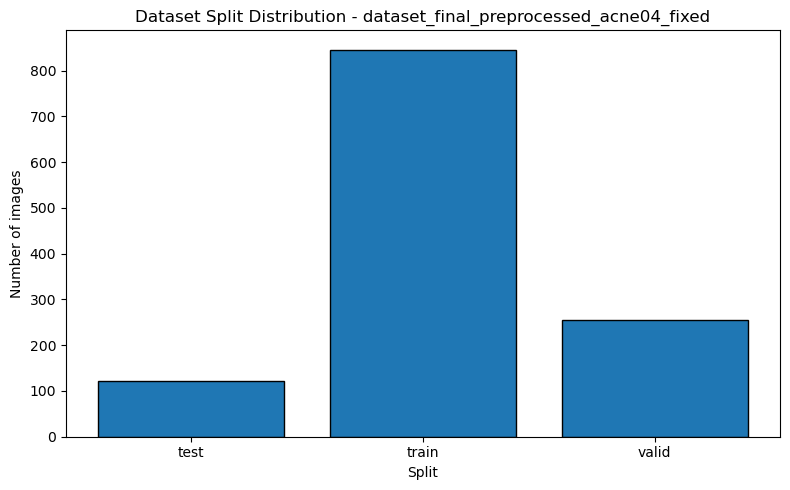

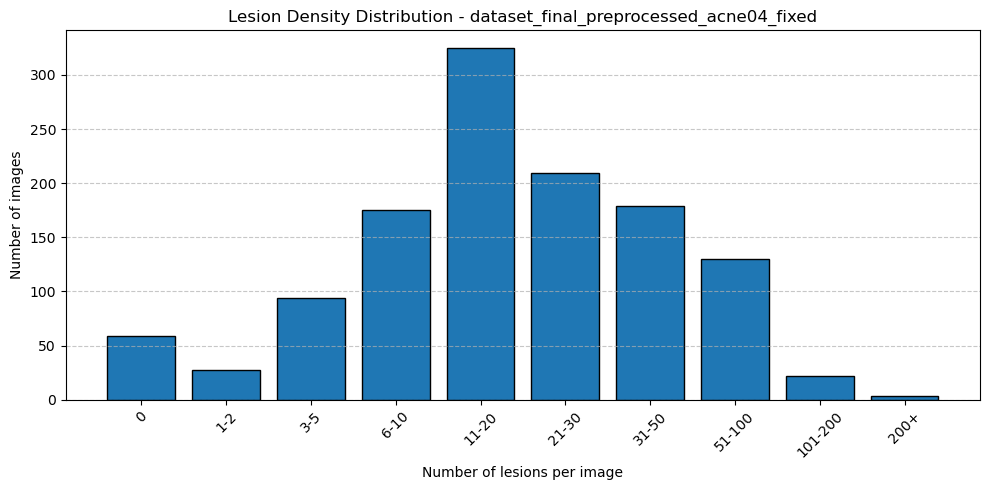

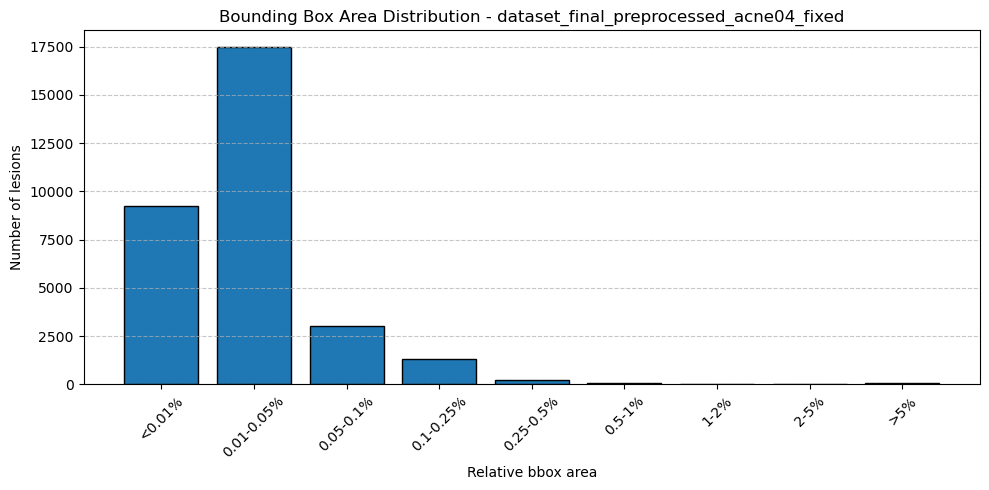

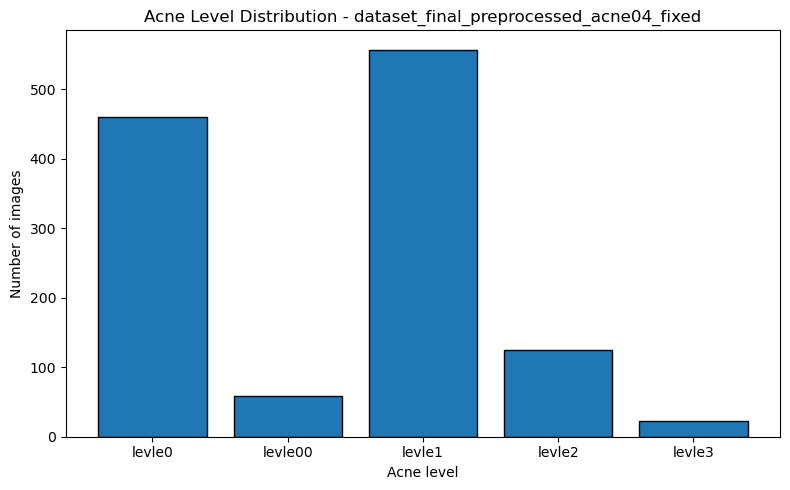

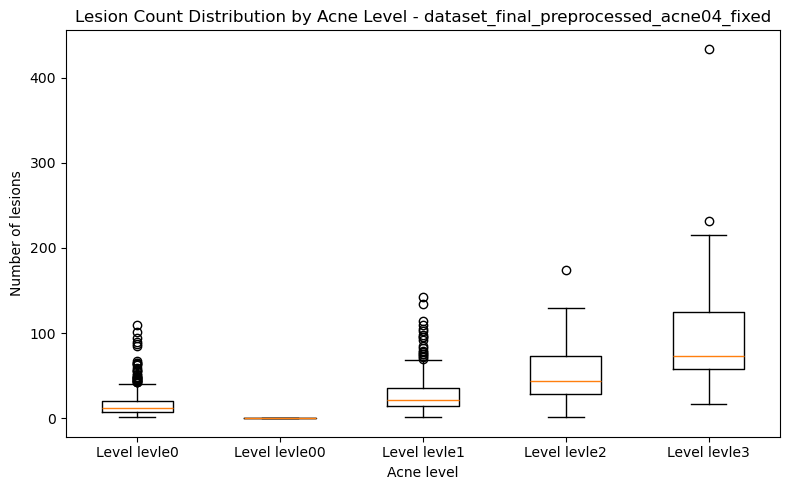

In [114]:
acne04=YoloDatasetAnalyzer(r"..\data\dataset_final_preprocessed_acne04_fixed",has_level=True)
results_acne04=acne04.run()

# Problems Analysis

In [117]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from PIL import Image

class YoloIssuesAnalyzer:
    """
    Dedicated analyzer for inspecting and visualizing dataset anomalies, 
    labeling errors, and out-of-bounds bounding boxes detected during initial dataset scanning.
    """
    def __init__(self, dataset_analyzer):
        """
        :param dataset_analyzer: Instantiated YoloDatasetAnalyzer that has already executed .analyze()
        """
        self.analyzer = dataset_analyzer
        self.dataset_dir = Path(dataset_analyzer.dataset_dir)
        self.issues_df = dataset_analyzer.issues_df
        self.bboxes_df = dataset_analyzer.bboxes_df
        self.images_df = dataset_analyzer.images_df

    def print_issues_summary(self):
        """Prints a targeted breakdown of all dataset issues."""
        print("=" * 70)
        print(f"DATASET ISSUES BREAKDOWN: {self.dataset_dir.name}")
        print("=" * 70)
        print(f"Total issue instances logged: {len(self.issues_df):,}")
        
        if not self.issues_df.empty:
            print("\nIssues by Type:")
            summary = self.issues_df["type"].value_counts().reset_index()
            summary.columns = ["Issue Type", "Count"]
            print(summary.to_string(index=False))
            
            if "split" in self.issues_df.columns:
                print("\nIssues per Split:")
                split_summary = pd.crosstab(self.issues_df["split"], self.issues_df["type"])
                print(split_summary.to_string())
        else:
            print("No issues detected in the dataset!")
        print("=" * 70 + "\n")

    def get_problematic_files(self, issue_type: str = None) -> pd.DataFrame:
        """
        Returns a table of all files containing errors.
        Optionally filter by a specific issue type (e.g., 'bbox_outside_image', 'corrupted_image').
        """
        if self.issues_df.empty:
            return pd.DataFrame()
        
        if issue_type:
            filtered = self.issues_df[self.issues_df["type"] == issue_type]
            return filtered.reset_index(drop=True)
        
        return self.issues_df.reset_index(drop=True)

    def visualize_random_outside_bbox(self, seed: int = None) -> pd.DataFrame | None:
        """
        Picks a random image with out-of-bounds bounding boxes, visualizes all its boxes 
        (highlighting faulty ones in red), and displays the detailed coordinate breakdown.
        """
        out_issues = self.issues_df[self.issues_df["type"] == "bbox_outside_image"] if not self.issues_df.empty else pd.DataFrame()
        
        if out_issues.empty:
            print("No out-of-bounds bounding boxes found in issues_df.")
            return None

        if seed is not None:
            random.seed(seed)
            
        sample_issue = out_issues.sample(1, random_state=seed).iloc[0]
        split = sample_issue["split"]
        file_stem = Path(sample_issue["file"]).stem

        # Retrieve image record to get full image name
        img_candidates = self.images_df[
            (self.images_df["split"] == split) & 
            (self.images_df["image"].map(lambda x: Path(x).stem) == file_stem)
        ]
        
        if img_candidates.empty:
            print(f"Image corresponding to file '{sample_issue['file']}' could not be loaded.")
            return None

        image_name = img_candidates.iloc[0]["image"]
        image_path = self.dataset_dir / split / "images" / image_name

        try:
            image = Image.open(image_path).convert("RGB")
        except Exception as err:
            print(f"Failed to open image {image_path}: {err}")
            return None

        img_width, img_height = image.size

        # Retrieve bounding boxes for this image
        image_bboxes = self.bboxes_df[
            (self.bboxes_df["split"] == split) & 
            (self.bboxes_df["image"] == image_name)
        ].copy()

        problematic_bboxes = image_bboxes[image_bboxes["outside"]]
        problematic_ids = problematic_bboxes["bbox_id"].tolist()

        print("=" * 70)
        print("RANDOM OUT-OF-BOUNDS BBOX EXAMPLE")
        print("=" * 70)
        print(f"Split:               {split}")
        print(f"Image:               {image_name}")
        print(f"Resolution:          {img_width} × {img_height} px")
        print(f"Total BBoxes:        {len(image_bboxes)}")
        print(f"Faulty BBoxes:       {len(problematic_bboxes)}")
        print(f"Faulty BBox IDs:     {problematic_ids}\n")

        # Plot bounding boxes
        fig, ax = plt.subplots(figsize=(12, 10))
        ax.imshow(image)

        for _, bbox in image_bboxes.iterrows():
            x1_px = bbox["x1_px"]
            y1_px = bbox["y1_px"]
            width_px = bbox["width_px"]
            height_px = bbox["height_px"]
            is_outside = bbox["outside"]

            edgecolor = "red" if is_outside else "limegreen"
            linewidth = 3 if is_outside else 1

            rect = Rectangle(
                (x1_px, y1_px), 
                width_px, 
                height_px, 
                fill=False, 
                edgecolor=edgecolor, 
                linewidth=linewidth
            )
            ax.add_patch(rect)
            ax.text(
                x1_px, y1_px, 
                str(int(bbox["bbox_id"])), 
                fontsize=9, 
                fontweight="bold", 
                color=edgecolor
            )

        ax.set_title(f"{image_name} | Split: {split} | {len(problematic_bboxes)} out-of-bounds box(es)")
        ax.axis("off")
        plt.tight_layout()
        plt.show()

        # Build coordinate summary table
        cols_to_display = [
            "bbox_id", "class_id", "center_x", "center_y",
            "width_relative", "height_relative",
            "x1_rel", "y1_rel", "x2_rel", "y2_rel",
            "x1_px", "y1_px", "x2_px", "y2_px", "outside"
        ]
        
        available_cols = [c for c in cols_to_display if c in image_bboxes.columns]
        bbox_table = image_bboxes[available_cols].copy()
        bbox_table["status"] = np.where(bbox_table["outside"], "OUTSIDE", "OK")
        bbox_table = bbox_table.rename(columns={"width_relative": "width", "height_relative": "height"})

        numeric_cols = bbox_table.select_dtypes(include=np.number).columns
        bbox_table[numeric_cols] = bbox_table[numeric_cols].round(4)

        return bbox_table

DATASET ISSUES BREAKDOWN: dataset_final_preprocessed_acne04_only
Total issue instances logged: 107

Issues by Type:
        Issue Type  Count
bbox_outside_image    107

Issues per Split:
type   bbox_outside_image
split                    
test                    6
train                  87
valid                  14

RANDOM OUT-OF-BOUNDS BBOX EXAMPLE
Split:               train
Image:               levle2_33.jpg
Resolution:          3112 × 3456 px
Total BBoxes:        125
Faulty BBoxes:       2
Faulty BBox IDs:     [67, 68]



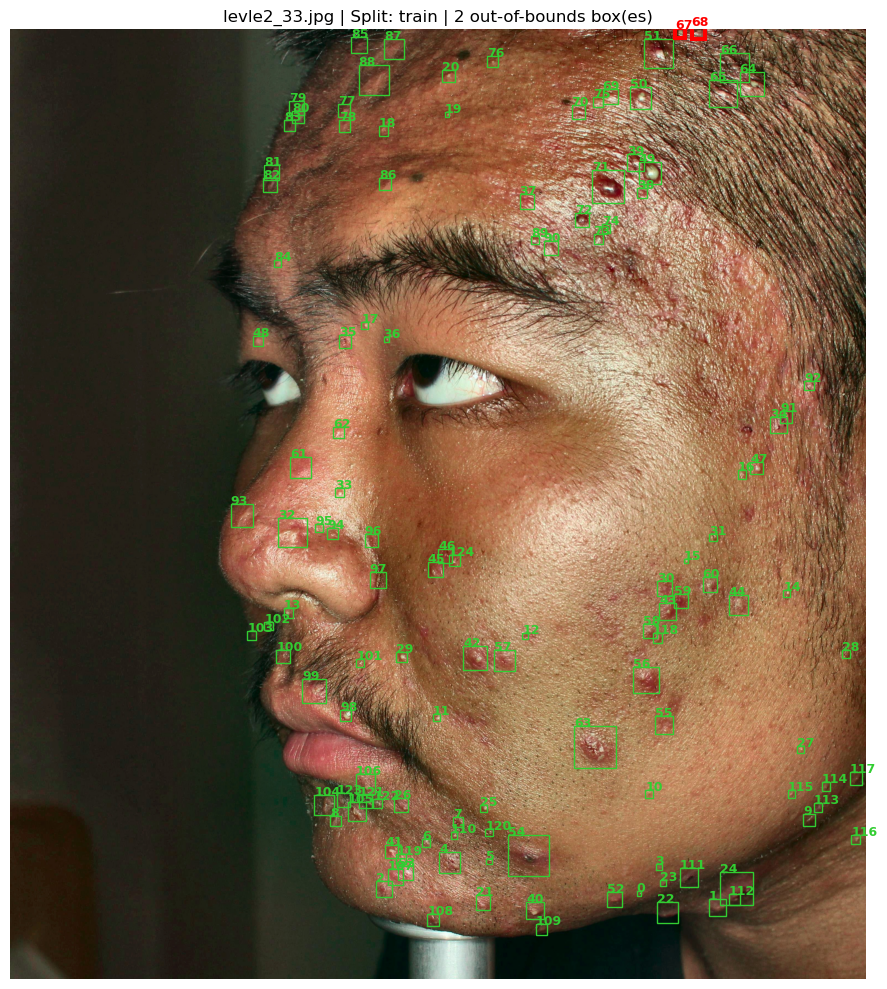

,bbox_id,class_id,center_x,center_y,width,height,x1_rel,y1_rel,x2_rel,y2_rel,x1_px,y1_px,x2_px,y2_px,outside,status
19074,0,0,0.7352,0.9097,0.0051,0.0046,0.7326,0.9074,0.7378,0.9120,2280.0021,3135.9986,2296.0009,3151.9999,False,OK
19075,1,0,0.8268,0.9245,0.0199,0.0179,0.8168,0.9155,0.8368,0.9334,2541.9983,3163.9991,2603.9987,3225.9997,False,OK
19076,2,0,0.4370,0.9054,0.0186,0.0168,0.4277,0.8970,0.4463,0.9138,1330.9993,3100.0009,1389.0007,3157.9995,False,OK
19077,3,0,0.7584,0.8822,0.0071,0.0064,0.7548,0.8791,0.7619,0.8854,2349.0014,3038.0003,2371.0001,3060.0012,False,OK
19078,4,0,0.5141,0.8773,0.0244,0.0220,0.5019,0.8663,0.5264,0.8883,1561.9999,2994.0002,1638.0012,3070.0011,False,OK
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19194,120,0,0.5601,0.8455,0.0090,0.0081,0.5556,0.8414,0.5646,0.8495,1729.0007,2907.9994,1756.9994,2935.9999,False,OK
19195,121,0,0.4152,0.8128,0.0154,0.0139,0.4075,0.8058,0.4229,0.8197,1268.0000,2784.9986,1315.9994,2832.9990,False,OK
19196,122,0,0.4299,0.8154,0.0103,0.0093,0.4248,0.8108,0.4351,0.8200,1322.0009,2802.0021,1354.0016,2834.0012,False,OK
19197,123,0,0.3898,0.8113,0.0161,0.0145,0.3817,0.8041,0.3978,0.8186,1187.9982,2779.0007,1237.9987,2829.0021,False,OK


In [118]:
# 1. Run your main dataset analyzer first
main_analyzer = YoloDatasetAnalyzer(r"..\data\dataset_final_preprocessed_acne04_only", has_level=True)
main_analyzer.analyze()

# 2. Pass the main analyzer into the issues analyzer
issue_analyzer = YoloIssuesAnalyzer(main_analyzer)

# 3. Print focused issue summary
issue_analyzer.print_issues_summary()

# 4. Get a table of all faulty files (e.g., only missing images or invalid formats)
corrupted_files = issue_analyzer.get_problematic_files("invalid_annotation_format")

# 5. Visualize a random out-of-bounds image example with bounding box table
bbox_table = issue_analyzer.visualize_random_outside_bbox(seed=42)
if bbox_table is not None:
    display(bbox_table)

RANDOM OUT-OF-BOUNDS BBOX EXAMPLE
Split:               train
Image:               levle2_130.jpg
Resolution:          3112 × 3456 px
Total BBoxes:        67
Faulty BBoxes:       49
Faulty BBox IDs:     [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48]



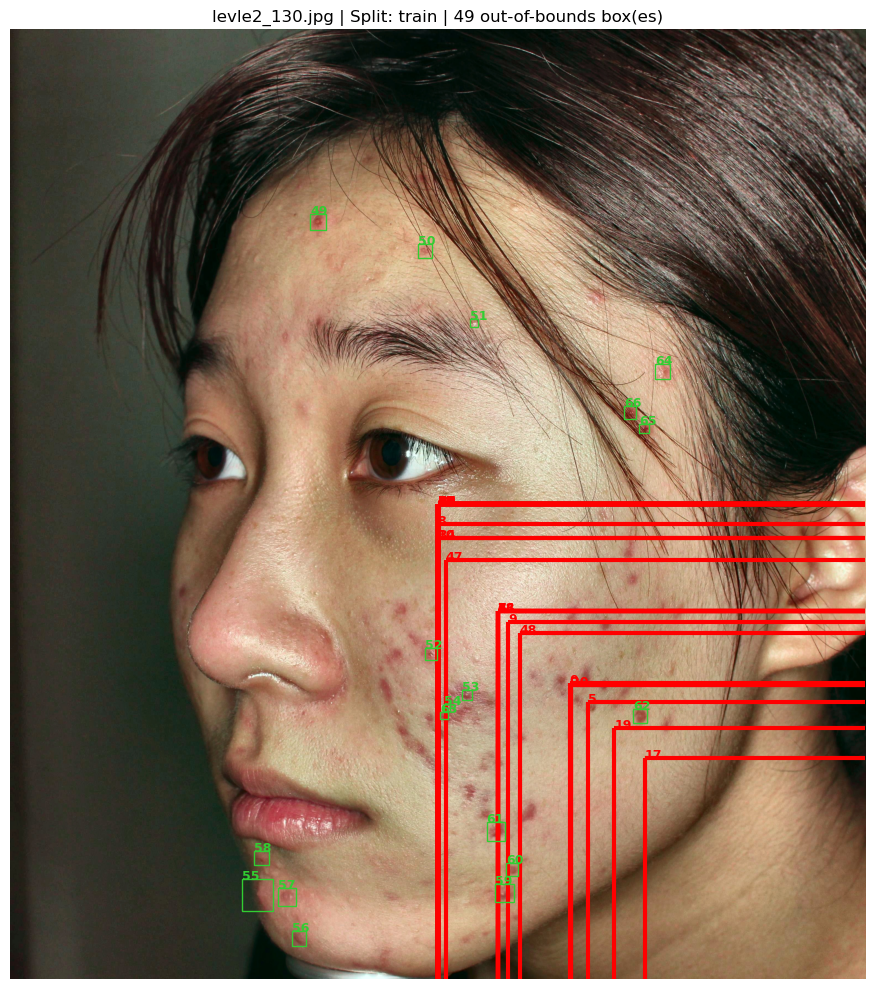

,bbox_id,class_id,center_x,center_y,width,height,x1_rel,y1_rel,x2_rel,y2_rel,x1_px,y1_px,x2_px,y2_px,outside,status
16623,0,0,1.0000,1.0000,0.6915,0.6227,0.6542,0.6887,1.3458,1.3113,2035.9995,2380.0003,4188.0005,4531.9997,True,OUTSIDE
16624,1,0,1.0000,1.0000,0.8599,0.7743,0.5701,0.6128,1.4299,1.3872,1774.0003,2117.9992,4449.9997,4794.0008,True,OUTSIDE
16625,2,0,1.0000,1.0000,0.6877,0.6192,0.6562,0.6904,1.3438,1.3096,2041.9995,2385.9999,4182.0005,4526.0001,True,OUTSIDE
16626,3,0,1.0000,1.0000,0.8599,0.7743,0.5701,0.6128,1.4299,1.3872,1774.0003,2117.9992,4449.9997,4794.0008,True,OUTSIDE
16627,4,0,1.0000,1.0000,0.8599,0.7743,0.5701,0.6128,1.4299,1.3872,1774.0003,2117.9992,4449.9997,4794.0008,True,OUTSIDE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16685,62,0,0.7365,0.7228,0.0167,0.0150,0.7281,0.7153,0.7449,0.7303,2265.9997,2472.0008,2318.0012,2523.9997,False,OK
16686,63,0,0.5077,0.7225,0.0090,0.0081,0.5032,0.7185,0.5122,0.7266,1566.0004,2483.0012,1593.9991,2511.0017,False,OK
16687,64,0,0.7629,0.3602,0.0167,0.0150,0.7545,0.3527,0.7712,0.3678,2347.9978,1219.0003,2399.9993,1270.9993,False,OK
16688,65,0,0.7413,0.4201,0.0109,0.0098,0.7359,0.4152,0.7468,0.4251,2290.0010,1435.0003,2323.9996,1469.0004,False,OK


In [125]:
bbox_table = issue_analyzer.visualize_random_outside_bbox(seed=1)
if bbox_table is not None:
    display(bbox_table)